# Experiment 5: Diabetes Prediction Comparison (KNN, Decision Tree, Random Forest)
**Aim:** To build and compare KNN, Decision Tree, and Random Forest models for diabetes prediction using classification evaluation metrics and confusion matrices.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

### A) Dataset Loading and Inspection

In [2]:
# Load dataset (update path if needed, e.g., '../Datasets/diabetes_dataset.csv')
df = pd.read_csv("../Datasets/diabetes_dataset.csv")

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Values:", df.duplicated().sum())

Dataset Shape: (768, 9)
Missing Values: 0
Duplicate Values: 0


### B) Data Splitting and Model Preparation

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "KNN": (KNeighborsClassifier(n_neighbors=25), X_train_scaled, X_test_scaled),
    "Decision Tree": (DecisionTreeClassifier(random_state=42), X_train, X_test),
    "Random Forest": (RandomForestClassifier(n_estimators=100, random_state=42), X_train, X_test)
}

### C) Model Training and Evaluation

        Model  Accuracy  Precision  Recall  F1-Score
          KNN     0.747      0.692   0.500     0.581
Decision Tree     0.727      0.643   0.500     0.562
Random Forest     0.760      0.681   0.593     0.634


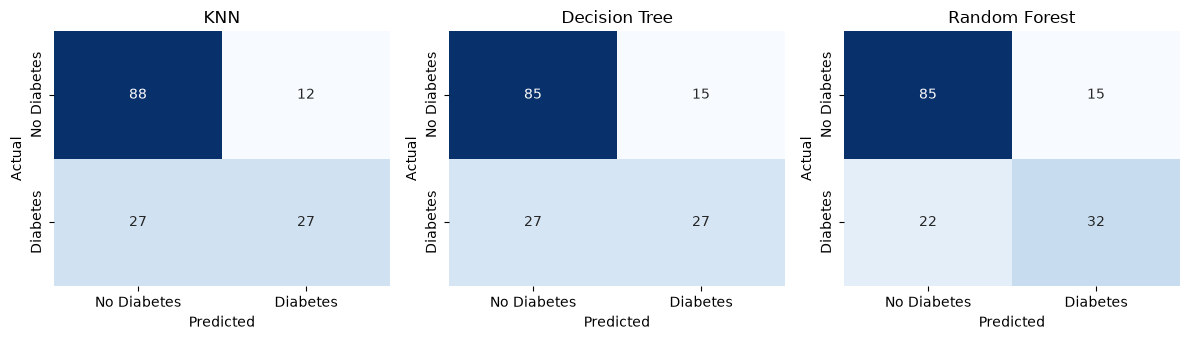

In [4]:
results = []
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

for ax, (name, (model, x_tr, x_te)) in zip(axes, models.items()):
    model.fit(x_tr, y_train)
    pred = model.predict(x_te)
    
    results.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred, zero_division=0),
        recall_score(y_test, pred, zero_division=0),
        f1_score(y_test, pred, zero_division=0)
    ])
    
    sns.heatmap(
        confusion_matrix(y_test, pred), annot=True, fmt="d",
        cmap="Blues", cbar=False, ax=ax,
        xticklabels=["No Diabetes", "Diabetes"],
        yticklabels=["No Diabetes", "Diabetes"]
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

print(pd.DataFrame(results, columns=[
    "Model", "Accuracy", "Precision", "Recall", "F1-Score"
]).round(3).to_string(index=False))

plt.tight_layout()
plt.show()